In [22]:
!pip install astrospice

In [23]:
!pip install sunpy

In [24]:
!pip install sunkit_magex

In [25]:
!pip install pfsspy

In [26]:
import os
import zipfile

In [27]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
#traceback 21
import pandas as pd
import numpy as np
import datetime
import astrospice
import sunpy.coordinates
import astropy.units as u
import matplotlib.pyplot as plt

df = pd.read_csv('/content/drive/MyDrive/424ph2013_transferred/WI_H1_SWE_2024_2025(v2).csv')

df.columns

Index(['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ', 'PROTON_BULK_SPEED_km/s',
       'P+_VX_GSE_NONLIN_km/s', 'P+_VY_GSE_NONLIN_km/s',
       'P+_VZ_GSE_NONLIN_km/s', 'P+_W_NONLIN_km/s', 'P+_DENSITY_cm^{-3}',
       'BX_nT', 'BY_nT', 'BZ_nT', 'XGSE_earth_radii', 'YGSE_earth_radii',
       'ZGSE_earth_radii'],
      dtype='object')

In [29]:
df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] = pd.to_datetime(df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'])

# CR 2293
start_date = '2025-01-06'
end_date   = '2025-02-03'

# Filter rows within that range
mask = (df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] >= start_date) & (df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] <= end_date)
df_sel = df.loc[mask]
df_sel = df.loc[mask].copy()


output_file = 'WIND_H1_5MIN_20250106_20250203.csv'
df_sel.to_csv(output_file, index=False)

print(f"Saved {len(df_sel)} rows to {output_file}")

Saved 18881 rows to WIND_H1_5MIN_20250106_20250203.csv


In [30]:
df_sel["PROTON_BULK_SPEED_km/s"][60:70]

,PROTON_BULK_SPEED_km/s
232079,569.235
232080,574.290
232081,555.099
232082,559.726
232083,559.748
232084,546.362
232085,546.159
232086,536.353
232087,533.469
232088,536.813


In [31]:
import astropy.units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord, CartesianRepresentation
from sunpy.coordinates import frames

df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] = pd.to_datetime(
    df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ']
)
obstimes = Time(df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'])

df_sel["XGSE_km"] = df_sel["XGSE_earth_radii"] * 6371.0
df_sel["YGSE_km"] = df_sel["YGSE_earth_radii"] * 6371.0
df_sel["ZGSE_km"] = df_sel["ZGSE_earth_radii"] * 6371.0

gse_cart = CartesianRepresentation(
    x=df_sel["XGSE_km"].values * u.km,
    y=df_sel["YGSE_km"].values * u.km,
    z=df_sel["ZGSE_km"].values * u.km,
)

sc_gse = SkyCoord(gse_cart, frame="geocentricsolarecliptic", obstime=obstimes)
sc_hci = sc_gse.transform_to(frames.HeliocentricInertial(obstime=obstimes))

# Save heliocentric Cartesian (km) and distance (AU)
df_sel["Helio_x_km"] = sc_hci.cartesian.x.to(u.km).value
df_sel["Helio_y_km"] = sc_hci.cartesian.y.to(u.km).value
df_sel["Helio_z_km"] = sc_hci.cartesian.z.to(u.km).value
df_sel["Helio_r_AU"] = sc_hci.distance.to(u.AU).value

# HCI to Carrington
sc_carr = sc_hci.transform_to(frames.HeliographicCarrington(obstime=obstimes, observer="sun"))
df_sel["Carr_lon_deg"] = sc_carr.lon.to(u.deg).value
df_sel["Carr_lat_deg"] = sc_carr.lat.to(u.deg).value
df_sel['Carr_r_km'] = sc_carr.radius.to(u.km).value
#df_sel["Carr_r_AU"]    = sc_carr.radius.to(u.AU).value

In [32]:
solar_rad = 696000  # km
source_surface_rad = 2.5 * solar_rad  # 2.5 R_s in km
sidereal_rotation_rate_degpersec = 360 / (27.2753 * 86400)  # degrees per second

#propagation time Delta t (in seconds)
df_sel['delta_t_s'] = (df_sel['Carr_r_km'] - source_surface_rad) / df_sel['PROTON_BULK_SPEED_km/s']

#longitudinal offset D (in degrees)
df_sel['longitude_offset_D_deg'] = sidereal_rotation_rate_degpersec * df_sel['delta_t_s']

#footpoint longitude at the source surface
df_sel['footpoint_lon_deg'] = (df_sel['Carr_lon_deg'] + df_sel['longitude_offset_D_deg']) % 360

df_sel['footpoint_lat_deg'] = df_sel['Carr_lat_deg']

print("correction results:")
print(df_sel[['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ', 'Carr_lon_deg', 'PROTON_BULK_SPEED_km/s',
              'delta_t_s', 'longitude_offset_D_deg', 'footpoint_lon_deg']].head(10))

df_sel.to_csv('wind_traceback21.csv', index=False)
print("\nData saved to 'wind_traceback21.csv'")

correction results:
         EPOCH_yyyy-mm-ddThh:mm:ss.sssZ  Carr_lon_deg  PROTON_BULK_SPEED_km/s  \
232019 2025-01-06 00:04:52.360000+00:00     10.776615                 593.746   
232020 2025-01-06 00:06:32.933000+00:00     10.761295                 586.462   
232021 2025-01-06 00:08:13.506000+00:00     10.745975                 565.541   
232022 2025-01-06 00:09:54.079000+00:00     10.730655                 569.525   
232023 2025-01-06 00:11:34.652000+00:00     10.715336                 562.106   
232024 2025-01-06 00:13:15.225000+00:00     10.700016                 566.523   
232025 2025-01-06 00:14:55.798000+00:00     10.684696                 548.382   
232026 2025-01-06 00:16:36.371000+00:00     10.669376                 555.038   
232027 2025-01-06 00:18:16.944000+00:00     10.654057                 557.530   
232028 2025-01-06 00:19:57.517000+00:00     10.638737                 559.840   

            delta_t_s  longitude_offset_D_deg  footpoint_lon_deg  
232019  242081.463428

In [33]:
df_sel[14640:14650] #find longitude for (for now) start date and end date of essw

,EPOCH_yyyy-mm-ddThh:mm:ss.sssZ,PROTON_BULK_SPEED_km/s,P+_VX_GSE_NONLIN_km/s,P+_VY_GSE_NONLIN_km/s,P+_VZ_GSE_NONLIN_km/s,P+_W_NONLIN_km/s,P+_DENSITY_cm^{-3},BX_nT,BY_nT,BZ_nT,...,Helio_y_km,Helio_z_km,Helio_r_AU,Carr_lon_deg,Carr_lat_deg,Carr_r_km,delta_t_s,longitude_offset_D_deg,footpoint_lon_deg,footpoint_lat_deg
246659,2025-01-27 14:37:02.028000+00:00,301.152,-300.881,-12.58360,-2.163310,18.1535,23.8756,-0.411135,-6.49426,-4.236040,...,1.140291e+08,-1.446647e+07,0.974760,86.430205,-5.693468,1.458220e+08,478436.213649,73.087527,159.517732,-5.693468
246660,2025-01-27 14:42:03.746000+00:00,300.929,-300.579,-11.46620,-8.870910,17.3976,21.8176,-0.447872,-5.08705,-6.366170,...,1.140347e+08,-1.446719e+07,0.974761,86.384242,-5.693749,1.458221e+08,478791.050612,73.141733,159.525975,-5.693749
246661,2025-01-27 14:43:44.318000+00:00,299.907,-299.646,-11.80990,-4.127540,18.4427,23.8837,0.127027,-6.56881,-4.256480,...,1.140366e+08,-1.446743e+07,0.974761,86.368921,-5.693843,1.458221e+08,480422.730269,73.390994,159.759915,-5.693843
246662,2025-01-27 14:48:46.036000+00:00,299.749,-299.388,-14.69380,-0.698206,18.8239,24.6974,0.448673,-7.77624,-1.423090,...,1.140422e+08,-1.446815e+07,0.974761,86.322958,-5.694124,1.458222e+08,480676.284509,73.429728,159.752686,-5.694124
246663,2025-01-27 14:50:26.609000+00:00,299.333,-299.000,-13.60430,3.790970,20.2582,23.0359,0.701307,-7.42894,-0.325454,...,1.140440e+08,-1.446839e+07,0.974762,86.307637,-5.694218,1.458223e+08,481344.400059,73.531791,159.839428,-5.694218
246664,2025-01-27 14:52:04.039000+00:00,298.541,-298.209,-13.68820,-3.230620,18.6002,22.0702,0.032156,-7.20939,-3.364950,...,1.140458e+08,-1.446862e+07,0.974762,86.292795,-5.694308,1.458223e+08,482621.450115,73.726878,160.019673,-5.694308
246665,2025-01-27 14:53:44.611000+00:00,301.640,-301.526,-6.22264,-5.437260,19.7539,24.3532,-0.515136,-4.76068,-5.512670,...,1.140477e+08,-1.446886e+07,0.974762,86.277474,-5.694402,1.458223e+08,477663.189269,72.969437,159.246911,-5.694402
246666,2025-01-27 14:55:25.184000+00:00,301.800,-301.695,-6.03149,-5.189790,19.3260,24.7215,-0.593147,-4.46830,-5.829160,...,1.140496e+08,-1.446910e+07,0.974762,86.262153,-5.694496,1.458224e+08,477410.046756,72.930766,159.192919,-5.694496
246667,2025-01-27 14:57:05.757000+00:00,302.741,-302.489,-8.76236,-8.715550,19.0641,23.2655,-0.453973,-4.17803,-6.404160,...,1.140514e+08,-1.446934e+07,0.974762,86.246832,-5.694589,1.458224e+08,475926.220148,72.704092,158.950924,-5.694589
246668,2025-01-27 14:58:46.329000+00:00,302.280,-302.188,-6.60808,-3.488210,19.4110,26.7305,-0.621347,-4.71343,-5.288200,...,1.140533e+08,-1.446958e+07,0.974763,86.231511,-5.694683,1.458224e+08,476652.156571,72.814988,159.046499,-5.694683


In [34]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Constants
rotation_days = 27.2753
total_degrees = 360
time_per_degree_in_day = rotation_days / total_degrees

# Start datetime of Carrington Rotation 2293
start_datetime = datetime.fromisoformat("2025-01-06T19:44")

degrees = np.arange(total_degrees, 0, -1) #longitude decreases from 360 to 0 from start to end date

day_numbers = np.arange(0, total_degrees) * time_per_degree_in_day

timestamps = [start_datetime + timedelta(days=day) for day in day_numbers]

dfs = pd.DataFrame({
    'Degree': degrees,
    'Timestamp': timestamps
})

In [41]:
dfs[200:230]

,Degree,Timestamp
200,160,2025-01-21 23:24:14.400
201,159,2025-01-22 01:13:20.472
202,158,2025-01-22 03:02:26.544
203,157,2025-01-22 04:51:32.616
204,156,2025-01-22 06:40:38.688
205,155,2025-01-22 08:29:44.760
206,154,2025-01-22 10:18:50.832
207,153,2025-01-22 12:07:56.904
208,152,2025-01-22 13:57:02.976
209,151,2025-01-22 15:46:09.048


In [42]:
import pandas as pd
from datetime import timedelta
start_time=pd.to_datetime("2025-01-22 01:13:20.472")
endtime=start_time+timedelta(hours=18)
endtime

Timestamp('2025-01-22 19:13:20.472000')

In [44]:
dfs[200:215]

,Degree,Timestamp
200,160,2025-01-21 23:24:14.400
201,159,2025-01-22 01:13:20.472
202,158,2025-01-22 03:02:26.544
203,157,2025-01-22 04:51:32.616
204,156,2025-01-22 06:40:38.688
205,155,2025-01-22 08:29:44.760
206,154,2025-01-22 10:18:50.832
207,153,2025-01-22 12:07:56.904
208,152,2025-01-22 13:57:02.976
209,151,2025-01-22 15:46:09.048


In [45]:
# Remove bad speeds
df_sel = df_sel[
    (df_sel['PROTON_BULK_SPEED_km/s'] > 0) &
    (df_sel['PROTON_BULK_SPEED_km/s'] < 2000)
]

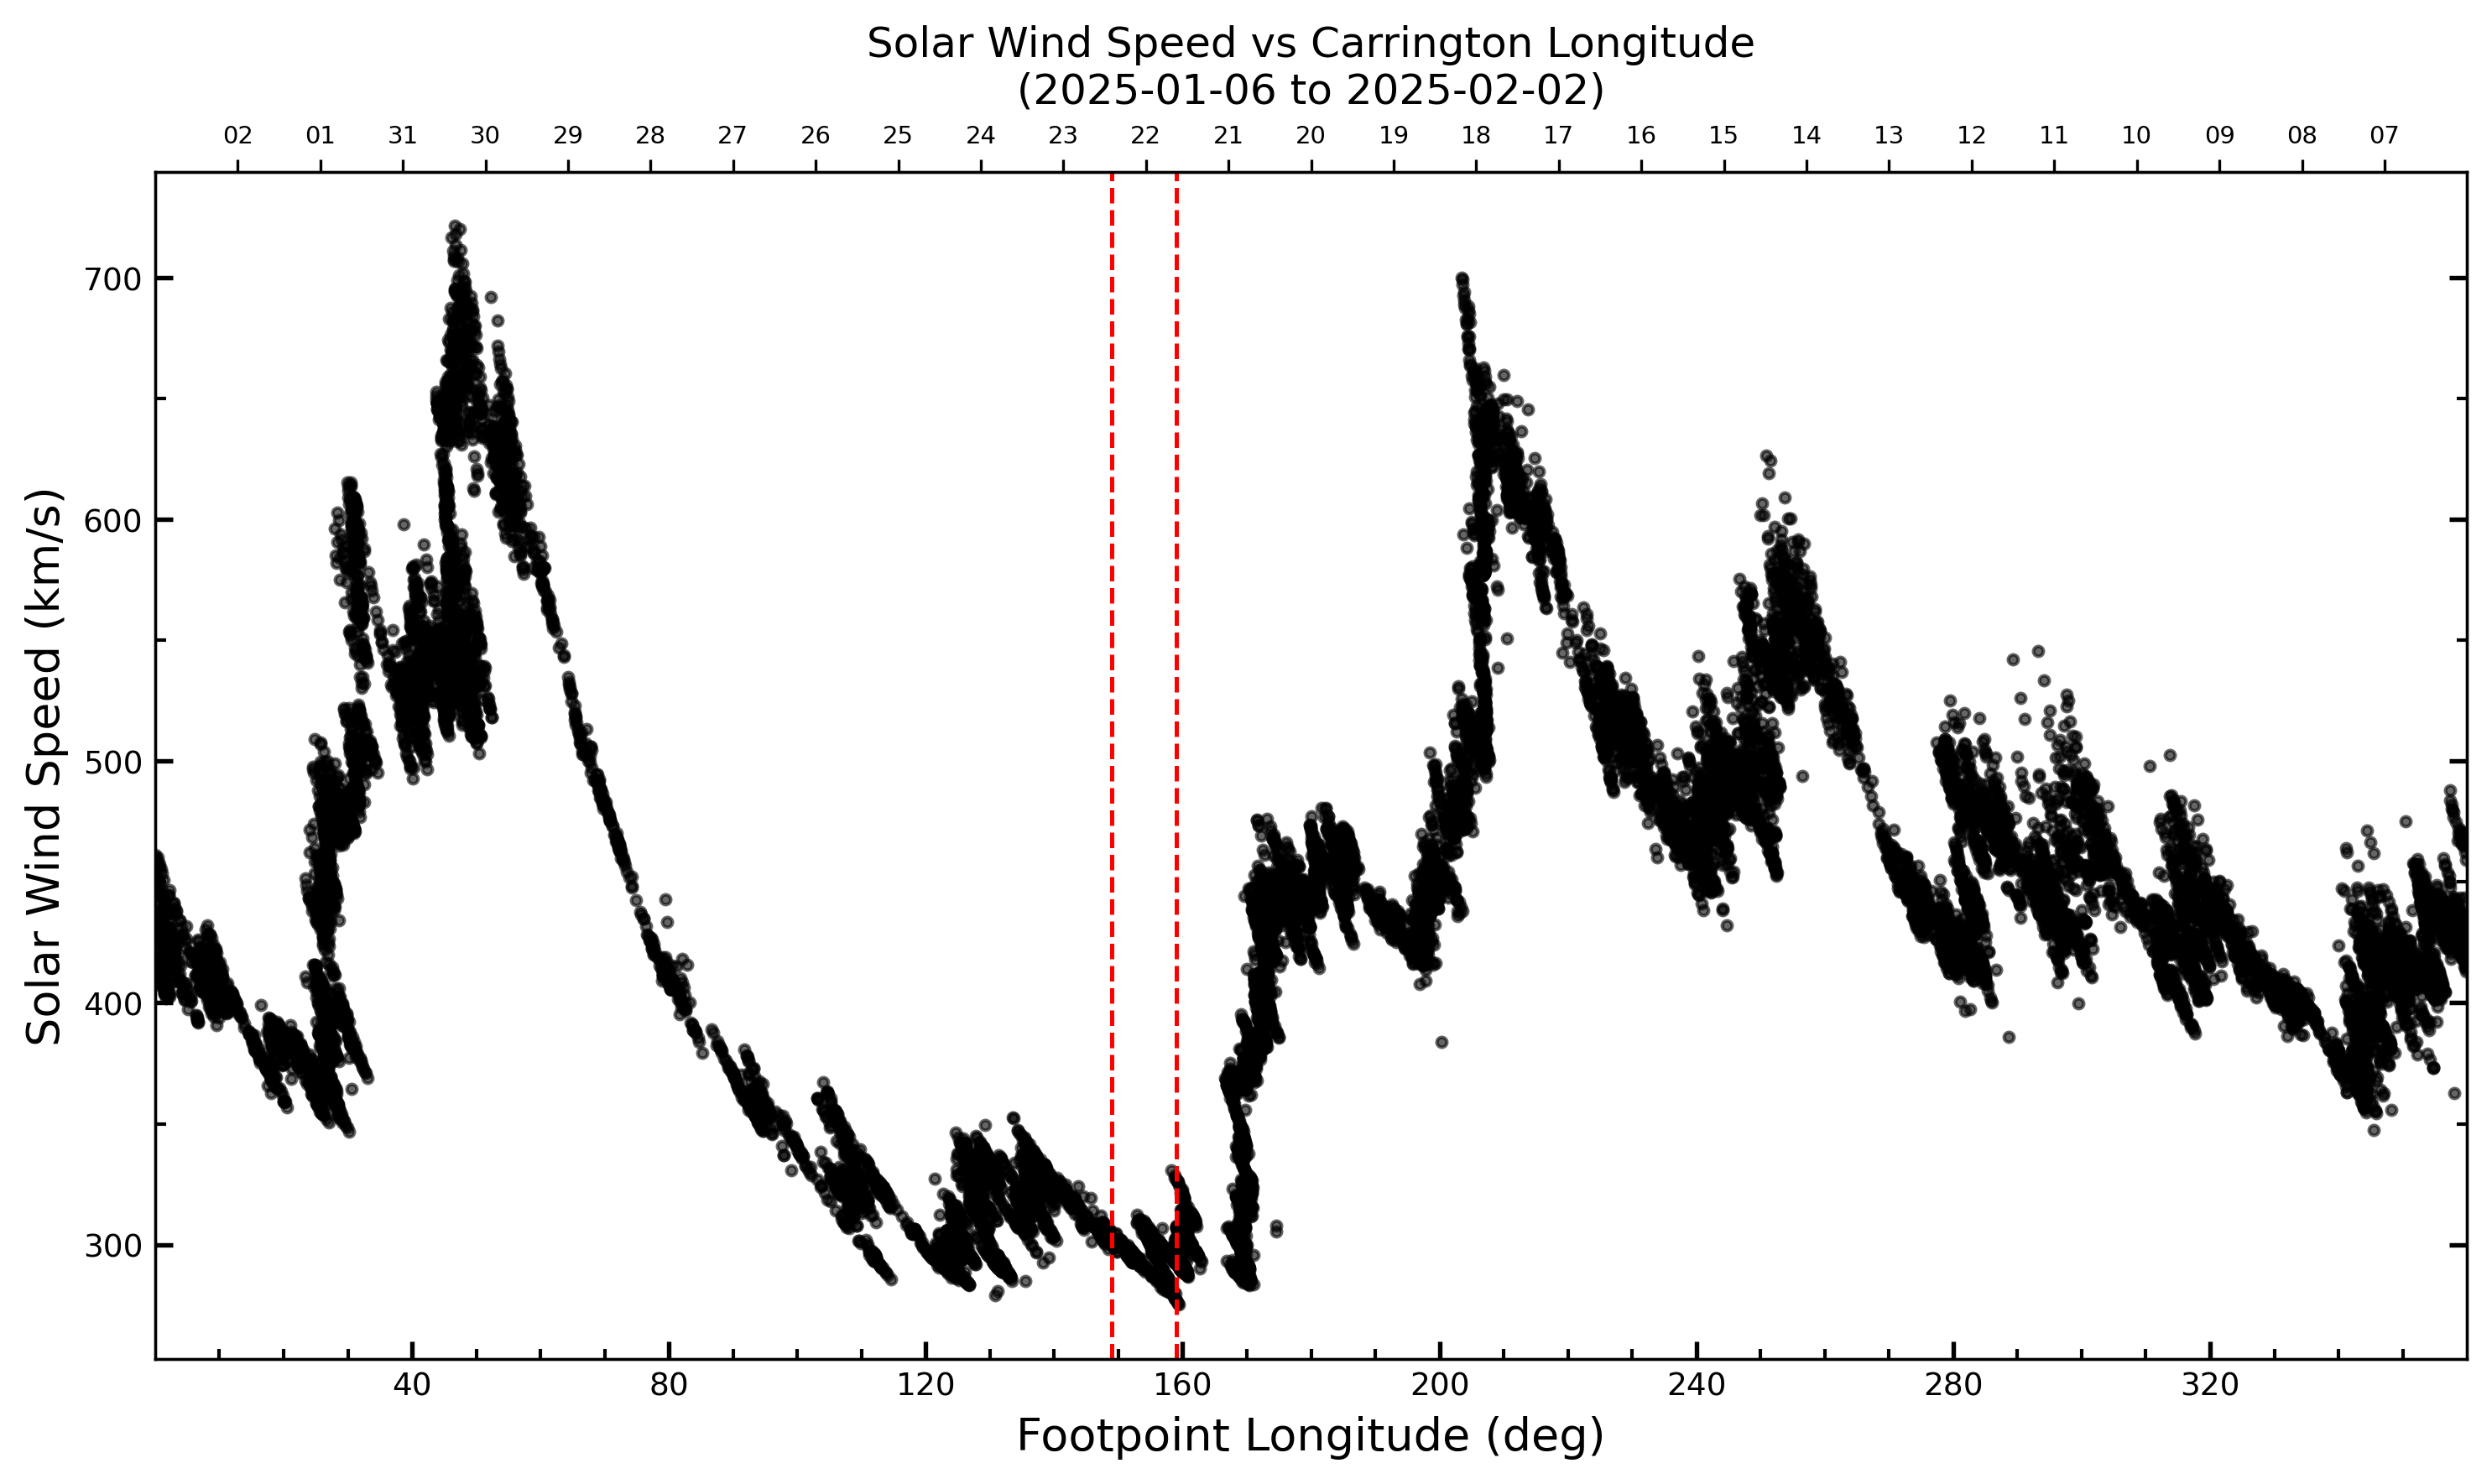

In [46]:
start_date = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].min().strftime("%Y-%m-%d")
end_date = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].max().strftime("%Y-%m-%d")
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator, MaxNLocator

# Ensure datetime format
df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] = pd.to_datetime(
    df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ']
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)


ax.scatter(df_sel['footpoint_lon_deg'],
           df_sel['PROTON_BULK_SPEED_km/s'],
           s=8, alpha=0.6, color='k', label="WIND data")

ax.set_xlabel("Footpoint Longitude (deg)", fontsize=13)
ax.set_ylabel("Solar Wind Speed (km/s)", fontsize=13)
ax.minorticks_on()
ax.yaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis='both', which='major', direction='in', length=5, width=1.3, labelsize=9)
ax.tick_params(axis='both', which='minor', direction='in', length=3, width=1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('both')

#ax.axhline(y=300, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='300 km/s threshold')
ax.axvline(x=159, color='r', linestyle='--', lw=1.2, label="Longitude range")
ax.axvline(x=149, color='r', linestyle='--', lw=1.2)

ax.xaxis.set_major_locator(MaxNLocator(10))
ax.set_xlim(min(df_sel['footpoint_lon_deg']),
            max(df_sel['footpoint_lon_deg']))

ax_top = ax.twiny()
formatter = mdates.DateFormatter('%d')   # show only day numbers
ax_top.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax_top.xaxis.set_major_formatter(formatter)


min_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].min()
max_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].max()
ax_top.set_xlim(max_time, min_time)   # reverse

plt.setp(ax_top.get_xticklabels(), rotation=0, ha='center', fontsize=7)

plt.title(f"Solar Wind Speed vs Carrington Longitude\n({min_time.date()} to {max_time.date()})")
plt.tight_layout()
plt.show()

In [47]:
pip install mpl-animators>=1.2.0 reproject>=0.12.0

In [48]:
import os
import matplotlib.pyplot as plt
import numpy as np

import astropy.units as u
from astropy.coordinates import SkyCoord

import sunpy.map
import sunkit_magex.pfss
import sunkit_magex.pfss.tracing as tracing

In [49]:
filenm ='/content/drive/MyDrive/424ph2013_transferred/ESSW_2026/hmi_maps/hmi.synoptic_mr_720s.2293.synopMr.fits'
hmi_map = sunpy.map.Map(filenm)
#print(hmi_map.meta)

In [50]:
import astropy.units as u
import pfsspy
import pfsspy.utils

# Fix HMI metadata
pfsspy.utils.fix_hmi_meta(hmi_map)

# PFSS parameters
nrho = 35
rss = 2.5

# Ensure CEA projection
if not pfsspy.utils.is_cea_map(hmi_map):
    hmi_map = pfsspy.utils.car_to_cea(hmi_map)  # reproject Carrington to CEA

# Downsample to speed up PFSS computation
hmi_map = hmi_map.resample([360, 180] * u.pix)

# fix nan
data = hmi_map.data
data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)  # replace all bad values with 0
hmi_map = hmi_map._new_instance(data, hmi_map.meta, hmi_map.plot_settings)


#print("Any NaNs left?", np.isnan(hmi_map.data).any())
#print("Any Infs left?", np.isinf(hmi_map.data).any())

# run pfss
pfss_in = pfsspy.Input(hmi_map, nrho, rss)
pfss_out = pfsspy.pfss(pfss_in)

/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

Text(0.5, 1.0, 'carr 2293 Source surface magnetic field at 2.5 Rs')

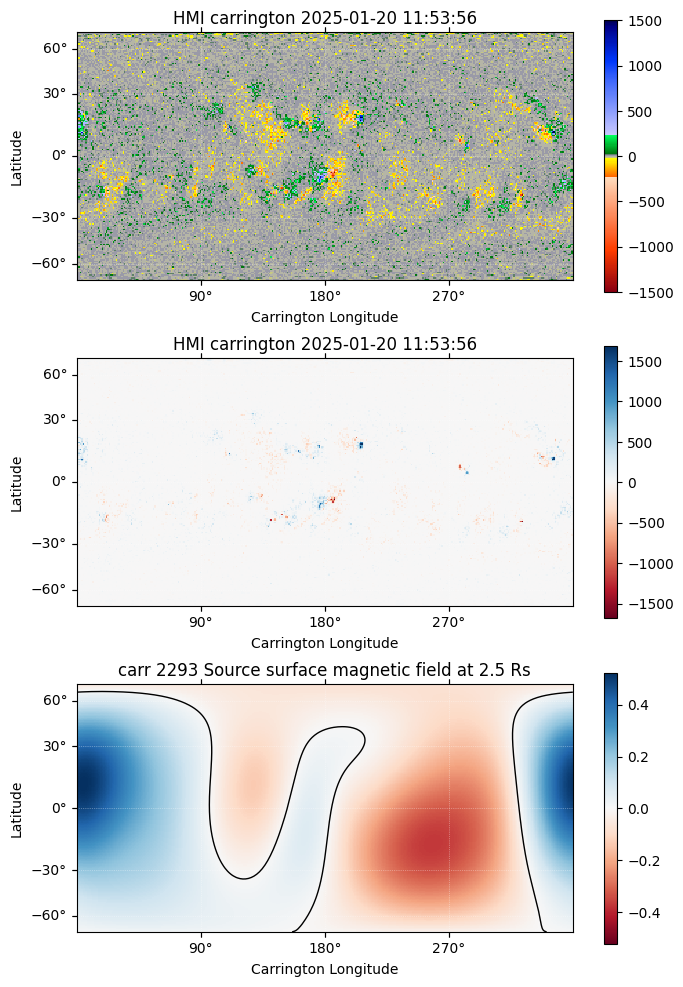

In [51]:
m=pfss_in.map
ss_br=pfss_out.source_surface_br


fig=plt.figure(figsize=(8,12))
ax=fig.add_subplot(3,1,1,projection=hmi_map)
hmi_map.plot()
plt.colorbar()
ax=fig.add_subplot(3,1,2,projection=m)
m.plot_settings['norm'].vmin = None
m.plot_settings['norm'].vmax = None
ax.set_title('Input HMI magnetogram')
m.plot(axes=ax)
plt.colorbar()
ax=fig.add_subplot(3,1,3,projection=ss_br)
ss_br.plot()
# plot the polarity inversion line
#ax.plot_coord(pfss_out.source_surface_pils[0])
for pil in pfss_out.source_surface_pils:
    ax.plot_coord(pil, color='k', linewidth=1)
plt.colorbar()
ax.set_title("carr "+str(2293)+" Source surface magnetic field at "+str(rss)+" Rs")

/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

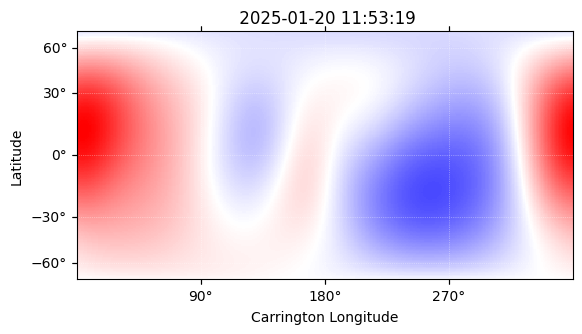

In [52]:
pfss_out.source_surface_br.plot(cmap='bwr')

In [53]:
# Define function which does the field line tracing
def pfss2flines(pfsspy_output, # pfsspy output object
                nth=18,nph=36, # number of tracing grid points
                rect=[-90,90,0,360], #sub-region of sun to trace (default is whole sun)
                trace_from_SS=False, # if False : start trace from photosphere,
                                     #if True, start tracing from source surface
                skycoord_in=None, # Use custom set of starting grid poitns
                max_steps = 1000 # max steps tracer should take before giving up
                ) :

    # Tracing if grid
    if skycoord_in is None  :
        [latmin,latmax,lonmin,lonmax]=rect
        lons,lats = np.meshgrid(np.linspace(lonmin,lonmax,nph),
                                np.linspace(latmin,latmax,nth)
                                )
        if not trace_from_SS : alt = 1.0*u.R_sun # Trace up from photosphere
        else : alt = pfsspy_output.grid.rss*u.R_sun  # Trace down from ss
        alt = [alt]*len(lons.ravel())
        seeds = astropy.coordinates.SkyCoord(lons.ravel()*u.deg,
                               lats.ravel()*u.deg,
                               alt,
                               frame = pfsspy_output.coordinate_frame)

    # Tracing if custom set of points
    else :
        skycoord_in.representation_type = "spherical"
        seeds = astropy.coordinates.SkyCoord(skycoord_in.lon,
                               skycoord_in.lat,
                               skycoord_in.radius,
                               frame = pfsspy_output.coordinate_frame)

    return pfsspy_output.trace(pfsspy.tracing.FortranTracer(max_steps=max_steps),seeds)

In [54]:
# from astropy.coordinates import SkyCoord
import astropy.coordinates
flines_highres = pfss2flines(pfss_out,nth=180,nph=360,rect=[-89.5,89.5,0.5,359.5])
#flines_highres = pfss2flines(pfss_out,nth=181,nph=361)

/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/tracing.py:180: UserWarning: At least one field line ran out of steps during tracing.
You should probably increase max_steps (currently set to 1000) and try again.
  warnings.warn(


In [55]:
topologies = flines_highres.polarities.reshape([180,360])

Text(0.5, 1.0, 'Coronal Hole Map Rss=2.5Rs')

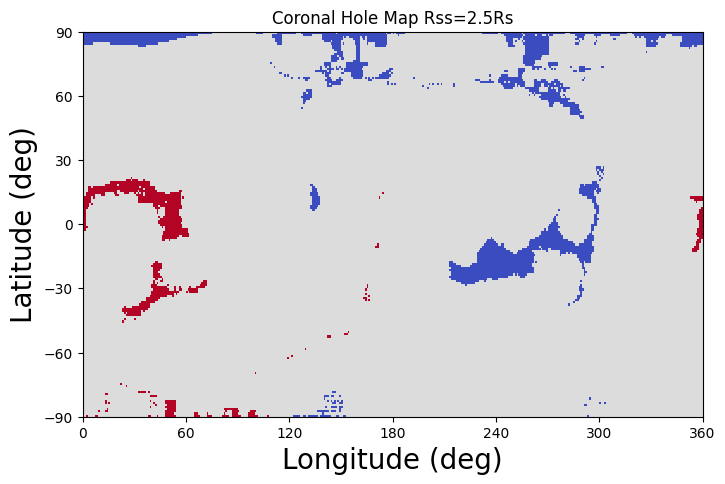

In [56]:
# lons = np.linspace(0,360,361)
# lats = np.linspace(-90,90,181)
lons = np.linspace(0.5,359.5,360)
lats = np.linspace(-89.5,89.5,180)
fig,ax = plt.subplots(figsize=(8,5))
ax.pcolormesh(lons,lats,topologies,cmap="coolwarm")
ax.set_xlabel("Longitude (deg)",fontsize=20)
ax.set_ylabel("Latitude (deg)",fontsize=20)
ax.set_xticks(np.linspace(0,360,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_title(f"Coronal Hole Map Rss=2.5Rs")

In [57]:
def source_surface_seeds(n_lon=92, n_lat=41, obstime=None):
    lon = np.linspace(0, 360, n_lon, endpoint=False)
    lat = np.arcsin(np.linspace(-0.5, 0.5, n_lat))
    lon_grid, lat_grid = np.meshgrid(lon, lat,indexing='ij')
    r = np.full_like(lat_grid, 2.5)
    return SkyCoord(
        lon_grid.flatten() * u.deg,
        lat_grid.flatten() * u.deg,
        r.flatten() * u.R_sun,
        frame='heliographic_carrington',
        obstime=obstime,
        observer='sun'
    )

tracer =pfsspy.tracing.FortranTracer(max_steps=8000,step_size=0.1)
seeds_all = source_surface_seeds(n_lon=92, n_lat=41, obstime=hmi_map.date)
flines = tracer.trace(seeds_all, pfss_out)

/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

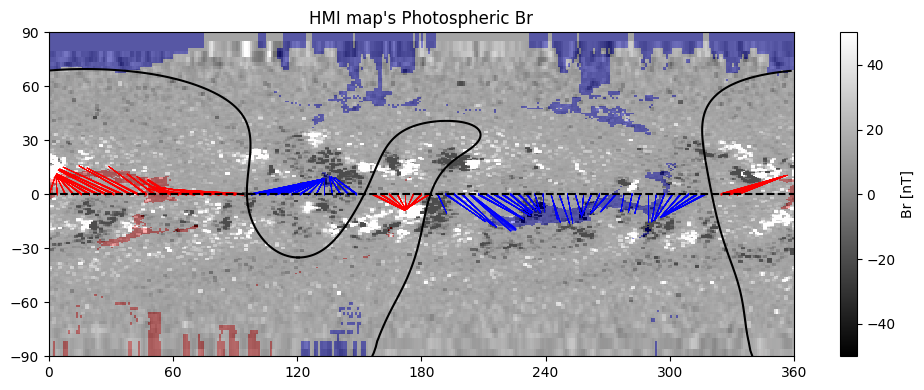

In [58]:
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

# Get longitude and latitude from PFSS output
lon = np.degrees(pfss_out.grid.pg)
lat = np.degrees(np.arcsin(pfss_out.grid.sg))
lon2, lat2 = np.meshgrid(lon, lat)

# Create the figure
fig, axes = plt.subplots(figsize=(10, 4))
axes.set_title("HMI map's Photospheric Br")

# Plot photospheric Br
c = axes.pcolor(
    lon, lat, pfss_out.bg[:, :, 0, 2].T,
    cmap='gray', norm=None,
    vmin=-50, vmax=50, shading='nearest'
)

# Plot Br=0 contour (neutral line / HCS)
axes.contour(
    lon[:-1], lat[:-1], pfss_out.source_surface_br.data,
    levels=[0], colors='k', linewidths=1.5
)

# Add colorbar
plt.colorbar(c, ax=axes, label="Br [nT]", orientation='vertical')

# Overlay topology map
axes.pcolormesh(lon2, lat2, topologies, cmap="bwr", alpha=0.3)

#  Polarity color mapping
color_dict = {-1: 'blue', 0: 'black', 1: 'red'}

# Plot magnetic field lines
for fline in flines:
    coords = fline.coords
    if len(coords.lon) == 0 or len(coords.lat) == 0:
        continue  # skip empty field lines

    # Convert coordinates
    lon_vals = coords.lon.to(u.deg).value % 360
    lat_vals = coords.lat.to(u.deg).value

    # Get polarity
    polarity = getattr(fline, "polarity", 0)
    color = color_dict.get(polarity, 'black')

    # Avoid wrap-around issue
    if np.abs(lon_vals[0] - lon_vals[-1]) < 200:
        axes.plot(
    [lon_vals[0], lon_vals[-1]],
    [lat_vals[0], lat_vals[-1]],
    color=color, lw=0.3, alpha=0.8
)

# Add equator line and axes formatting
plt.axhline(y=0, color='k', linestyle='--')
axes.set_xticks(np.linspace(0, 360, 7))
axes.set_yticks(np.linspace(-90, 90, 7))
axes.set_xlim([0, 360])
axes.set_ylim([-90, 90])

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.13/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

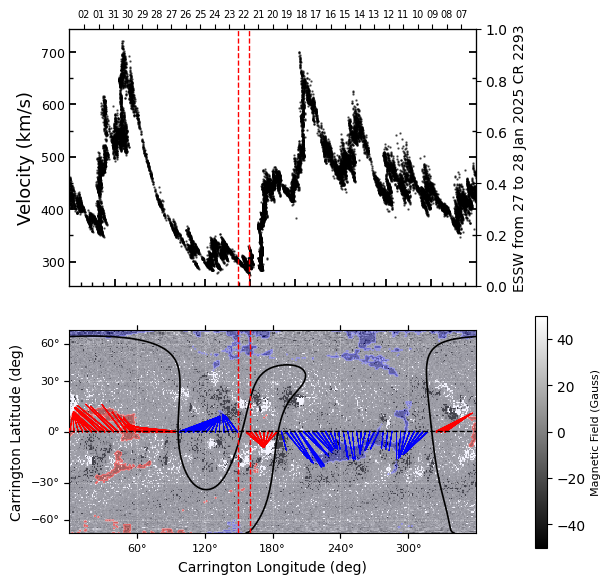

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator, MaxNLocator
import astropy.units as u
import matplotlib.colors as mcolor
from astropy.coordinates import SkyCoord
from astropy.visualization.wcsaxes import formatter_locator

# FIGURE 1: Velocity vs Footpoint Longitude
fig = plt.figure(figsize=(6, 6), constrained_layout=True)

# Upper panel
ax = fig.add_subplot(2, 1, 1)
ax.scatter(
    df_sel['footpoint_lon_deg'],
    df_sel['PROTON_BULK_SPEED_km/s'],
    color='k', alpha=0.6, s=0.5
)

ax.set_xticklabels([])
ax.set_ylabel('Velocity (km/s)', fontsize=13)

# Twin y-axis
ax_right = ax.twinx()
ax_right.set_ylabel("ESSW from 27 to 28 Jan 2025 CR 2293", fontsize=10)

# Tick formatting
ax.minorticks_on()
ax.yaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis='both', which='major', direction='in', length=5, width=1.3, labelsize=9)
ax.tick_params(axis='both', which='minor', direction='in', length=3, width=1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('both')

# Vertical markers
plt.axvline(x=159, color='r', linestyle='--', lw=1)
plt.axvline(x=149, color='r', linestyle='--', lw=1)

# Limits
ax.xaxis.set_major_locator(MaxNLocator(10))
ax.set_xlim(
    min(df_sel['footpoint_lon_deg']),
    max(df_sel['footpoint_lon_deg'])
)

# Twin x-axis (dates)
ax_top = ax.twiny()
formatter = mdates.DateFormatter('%d')
ax_top.xaxis.set_major_locator(MaxNLocator(29))
ax_top.xaxis.set_major_formatter(formatter)

min_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].min()
max_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].max()
ax_top.set_xlim(max_time, min_time)
plt.setp(ax_top.get_xticklabels(), rotation=0, ha='center', fontsize=7)

# FIGURE 2: PFSS / HMI Map
ax2 = fig.add_subplot(2, 1, 2, projection=hmi_map)

# Neutral line (HCS)
#if hasattr(pfss_out, 'source_surface_pils') and len(pfss_out.source_surface_pils) > 0:
#    ax2.plot_coord(pfss_out.source_surface_pils[0], color='k', linewidth=1)
if hasattr(pfss_out, 'source_surface_pils') and len(pfss_out.source_surface_pils) > 0:
    for pil in pfss_out.source_surface_pils:
        if pil is None or len(pil.lon) == 0:
            continue
        try:
            ax2.plot_coord(pil, color='k', linewidth=1.2)
        except Exception:
            continue

# HMI background
im = hmi_map.plot(axes=ax2, cmap='gray', norm=None, vmin=-50.0, vmax=50.0)

# Colorbar
cbar = fig.colorbar(im, pad=0.02, shrink=0.9, ax=ax2)
cbar.set_label('Magnetic Field (Gauss)', size=8)

# Topology overlay
ax2.contourf(topologies, cmap='bwr', norm=None, alpha=0.3)

# Polarity mapping
color_dict = {-1: 'blue', 0: 'black', 1: 'red'}

# Field lines
for fline in flines:
    coords = fline.coords
    if len(coords.lon) == 0 or len(coords.lat) == 0:
        continue

    lon_start = coords.lon[0].to(u.deg).value
    lat_start = coords.lat[0].to(u.deg).value
    lon_end   = coords.lon[-1].to(u.deg).value
    lat_end   = coords.lat[-1].to(u.deg).value

    polarity = getattr(fline, "polarity", 0)
    color = color_dict.get(polarity, 'black')

    # Avoid wrap-around
    if np.abs(lon_start - lon_end) < 200:
        try:
            ax2.plot_coord(
                SkyCoord(
                    [lon_start, lon_end],
                    [lat_start, lat_end],
                    unit='deg',
                    frame=hmi_map.coordinate_frame
                ),
                color=color,
                linewidth=0.3,   #thinner lines
                alpha=0.8
            )
        except Exception:
            continue

# Coordinate formatting
lon = ax2.coords[0]
lat = ax2.coords[1]

lon.set_ticks([0, 60, 120, 180, 240, 300, 360] * u.deg)
lon.set_ticklabel_position('b')
lon.set_ticklabel(size=8)
lon.set_axislabel("Carrington Longitude (deg)", fontsize=10)
lon.set_major_formatter('d')

lat.set_ticks([-90, -60, -30, 0, 30, 60, 90] * u.deg)
lat.set_ticklabel(size=8)
lat.set_axislabel("Carrington Latitude (deg)", fontsize=10)
lat.set_major_formatter('d')

# Markers
ax2.set_title("")
ax2.axvline(x=(159 * u.deg).value, color='red', linestyle='--', linewidth=1)
ax2.axvline(x=(149* u.deg).value, color='red', linestyle='--', linewidth=1)
ax2.axhline(y=90, color='black', linestyle='--', linewidth=1)

plt.show()